In [169]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dropout, Dense, Flatten, Conv2D, MaxPool2D, BatchNormalization
# layers for data augmentation
from tensorflow.keras.layers import RandomZoom, RandomTranslation, RandomBrightness, RandomRotation

from matplotlib import pyplot as plt

import pandas as pd

## loading the Sign-Language MNIST hand gestures dataset
![MNIST sign-language gestures](mnist_american_sign_language.png "MNIST sign-language gestures")

In [170]:
train = pd.read_csv("sign_mnist_train.csv")
test = pd.read_csv("sign_mnist_test.csv")

labels = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']

X_train = train.iloc[:, 1:].to_numpy().reshape(-1, 28, 28)
y_train = train.iloc[:, 0].to_numpy()
X_test = test.iloc[:, 1:].to_numpy().reshape(-1, 28, 28)
y_test = test.iloc[:, 0].to_numpy()

## shapes of train and test data

In [171]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print()
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (27455, 28, 28)
y_train: (27455,)

X_test: (7172, 28, 28)
y_test: (7172,)


## show the first 12 training hand gestures

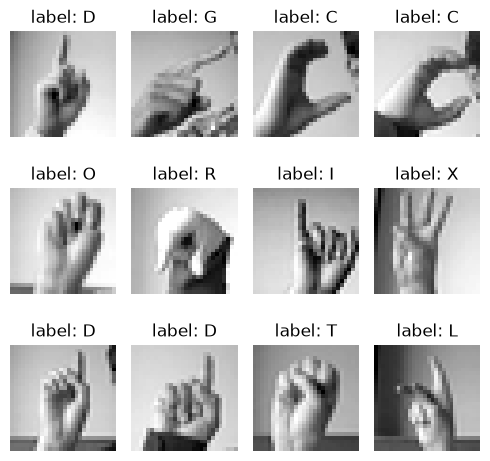

In [172]:
plt.figure(figsize=(5,5))
for k in range(12):
    subplt = plt.subplot(3, 4, k+1)
    subplt.set_title(f"label: {labels[y_train[k]]}")
    plt.imshow(X_train[k], cmap='gray')
    plt.axis('off')
plt.tight_layout()
plt.show()

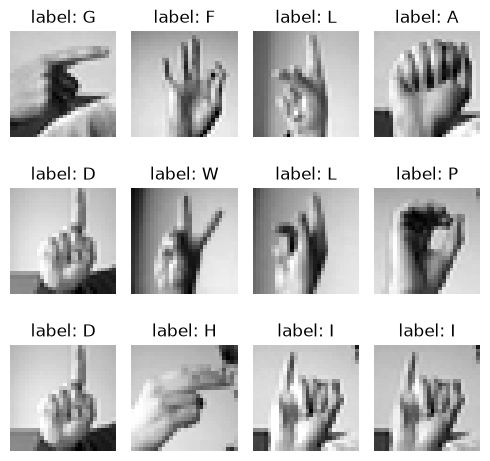

In [173]:
# show the first 12 test hand gestures

plt.figure(figsize=(5,5))
for k in range(12):
    subplt = plt.subplot(3, 4, k+1)
    subplt.set_title(f"label: {labels[y_test[k]]}")
    plt.imshow(X_test[k], cmap='gray')
    plt.axis('off')
plt.tight_layout()
plt.show()

## adjust the traning and testing input

In [174]:
X_train = X_train.reshape(-1, 28, 28, 1).astype('float32') / 255
X_test = X_test.reshape(-1, 28, 28, 1).astype('float32') / 255

from sklearn.preprocessing import LabelBinarizer
label_binarizer = LabelBinarizer()
y_train = label_binarizer.fit_transform(y_train)
y_test = label_binarizer.fit_transform(y_test)

## data augmentation and preparing for training

In [175]:
datagen = Sequential([
    RandomRotation(
        factor=10/360,
        fill_mode="nearest"
    ),
    RandomZoom(
        height_factor=0.1,
        width_factor=0.1,
        fill_mode="nearest"
    ),
    RandomTranslation(
        height_factor=0.1,
        width_factor=0.1,
        fill_mode="nearest"
    ),
    RandomBrightness(
        factor=0.1,
        value_range=(0, 1)
    ),
], name="data_augmentation")

train_dataset = (
    tf.data.Dataset
        .from_tensor_slices((X_train, y_train))
        .shuffle(1024)
        .batch(128)
        .map(
            lambda x, y: (datagen(x, training=True), y),
            num_parallel_calls=(tf.data.AUTOTUNE)
        )
)

## building the model

In [176]:
model = Sequential()
model.add(Input(shape=(28, 28, 1)))
model.add(Conv2D(75 , (3, 3) , strides = 1 , padding = 'same' , activation = 'relu'))
model.add(BatchNormalization())
model.add(MaxPool2D((2, 2) , strides = 2 , padding = 'same'))
model.add(Conv2D(50 , (3, 3) , strides = 1 , padding = 'same' , activation = 'relu'))
model.add(Dropout(0.2))
model.add(BatchNormalization())
model.add(MaxPool2D((2, 2) , strides = 2 , padding = 'same'))
model.add(Conv2D(25 , (3, 3) , strides = 1 , padding = 'same' , activation = 'relu'))
model.add(BatchNormalization())
model.add(MaxPool2D((2, 2) , strides = 2 , padding = 'same'))
model.add(Flatten())
model.add(Dense(units = 512 , activation = 'relu'))
model.add(Dropout(0.3))
model.add(Dense(units = 24 , activation = 'softmax'))
model.compile(optimizer = 'adam' , loss = 'categorical_crossentropy' , metrics = ['accuracy'])

## visualization of trainable CNN

In [177]:
model.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_36 (Conv2D)              │ (None, 28, 28, 75)     │           750 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_36          │ (None, 28, 28, 75)     │           300 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_36 (MaxPooling2D) │ (None, 14, 14, 75)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_37 (Conv2D)              │ (None, 14, 14, 50)     │        33,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ (None, 14, 14, 50)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_37          │ (None, 14, 14, 50)     │           200 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_37 (MaxPooling2D) │ (None, 7, 7, 50)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_38 (Conv2D)              │ (None, 7, 7, 25)       │        11,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_38          │ (None, 7, 7, 25)       │           100 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_38 (MaxPooling2D) │ (None, 4, 4, 25)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_12 (Flatten)            │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 512)            │       205,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 24)             │        12,312 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 264,049 (1.01 MB)

 Trainable params: 263,749 (1.01 MB)

 Non-trainable params: 300 (1.17 KB)

/mnt/c/Users/a.zamoysky/esp32-s3_test/model/.venv/lib/python3.14/site-packages/visualkeras/layered.py:231: UserWarning: The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.
  warnings.warn("The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.")


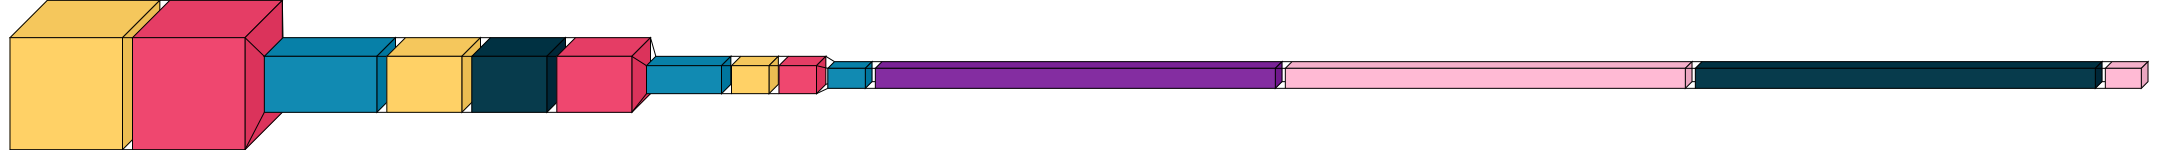

In [178]:
import visualkeras

for layer in model.layers:
    if not hasattr(layer, 'output_shape'):
        layer.output_shape = layer.output.shape
        
visualkeras.layered_view(model).show()

## training the model

In [179]:
history = model.fit(train_dataset, epochs=20, validation_data=(X_test, y_test))

Epoch 1/20


/mnt/c/Users/a.zamoysky/esp32-s3_test/model/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 42ms/step - accuracy: 0.6427 - loss: 1.1521 - val_accuracy: 0.0637 - val_loss: 4.0285
Epoch 2/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9168 - loss: 0.2485 - val_accuracy: 0.6514 - val_loss: 1.0090
Epoch 3/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - accuracy: 0.9620 - loss: 0.1183 - val_accuracy: 0.9529 - val_loss: 0.1668
Epoch 4/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9763 - loss: 0.0769 - val_accuracy: 0.9706 - val_loss: 0.0793
Epoch 5/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9823 - loss: 0.0564 - val_accuracy: 0.9782 - val_loss: 0.0754
Epoch 6/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.9878 - loss: 0.0399 - val_accuracy: 0.9859 - val_loss: 0.0524
Epoch 7/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9882 - loss: 0.0354 - val_accuracy: 0.9856 - val_loss: 0.0539
Epoch 8/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9896 - loss: 0.0326 - val_accuracy: 0.97

## analysis after model training

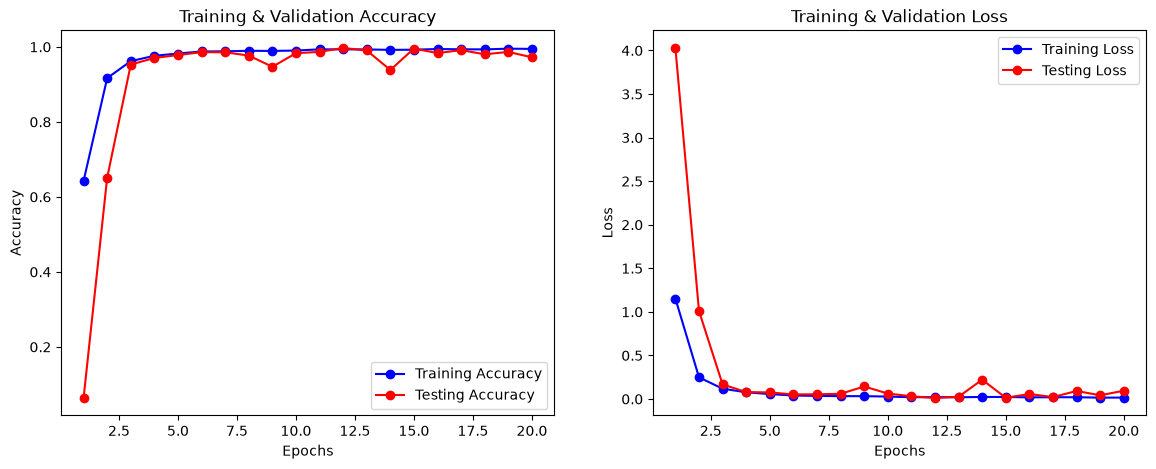

In [180]:
train_acc = history.history['accuracy']
train_loss = history.history['loss']
val_acc = history.history['val_accuracy']
val_loss = history.history['val_loss']

epochs = range(1, len(train_loss) + 1)

fig , ax = plt.subplots(1,2)
fig.set_size_inches(14,5)

ax[0].plot(epochs , train_acc , 'bo-' , label = 'Training Accuracy')
ax[0].plot(epochs , val_acc , 'ro-' , label = 'Testing Accuracy')
ax[0].set_title('Training & Validation Accuracy')
ax[0].legend()
ax[0].set_xlabel("Epochs")
ax[0].set_ylabel("Accuracy")

ax[1].plot(epochs , train_loss , 'bo-' , label = 'Training Loss')
ax[1].plot(epochs , val_loss , 'ro-' , label = 'Testing Loss')
ax[1].set_title('Training & Validation Loss')
ax[1].legend()
ax[1].set_xlabel("Epochs")
ax[1].set_ylabel("Loss")
plt.show()